# Naive Bayes

Naive Bayes learns the average and spread of each feature in each species, then asks which species a new penguin **looks more like**.

This notebook goes with the **Naive Bayes** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split into train and test → scale → fit the model → check the result → draw the decision boundary.

## 1. Load the data

Each row is a penguin. We have two measurements (**bill length** and **body mass**) and the species. The goal: predict whether a penguin is an **Adelie** or a **Chinstrap** from those two numbers.

The data is the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) data set (CC0), reduced to two species and two columns.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/penguins.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,species,bill_length_mm,body_mass_g
0,Adelie,39.1,3750
1,Adelie,39.5,3800
2,Adelie,40.3,3250
3,Adelie,36.7,3450
4,Adelie,39.3,3650


In [2]:
X = dataset[['bill_length_mm', 'body_mass_g']].values
y = (dataset['species'] == 'Chinstrap').astype(int).values  # 0 = Adelie, 1 = Chinstrap

print(X.shape, 'penguins, class counts:', np.bincount(y))

(219, 2) penguins, class counts: [151  68]


## 2. Split into train and test

The model learns from the **training** penguins (75%). We keep the other 25% hidden and only use them at the end, so the test score shows how the model does on penguins it has never seen. Those are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

164 train, 55 test


## 3. Scale the features

Naive Bayes does not need scaling. We scale anyway so the plotting code stays the same in every notebook.

`StandardScaler` shifts each feature to an average of 0 and a spread of 1. We fit it on the **training** data only, then apply it to both sets.

In [4]:
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)

## 4. Fit the model

This is the same code as on the lesson's Code tab (with `X_train_s` and `y_train`).

In [5]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train_s, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[117., 47.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.71,0.29]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[-0.54,-0.04], [ 1.34, 0.11]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[0.25,1.09], [0.36,0.76]]"


## 5. Check the result

The **confusion matrix** counts right and wrong guesses: the diagonal is correct, everything else is a mistake. **Accuracy** is the share of test penguins the model got right.

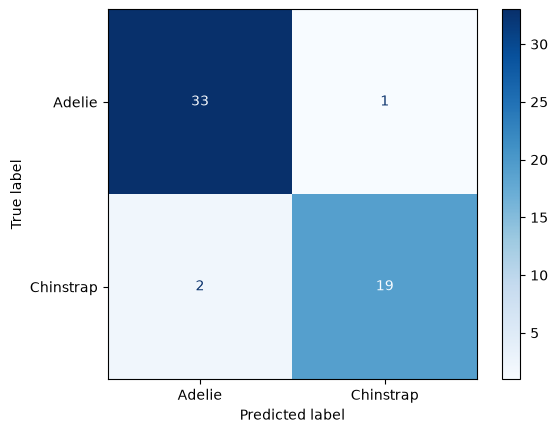

Test accuracy:  0.945
Train accuracy: 0.957


In [6]:
y_pred = classifier.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Adelie', 'Chinstrap']).plot(cmap='Blues')
plt.show()

print('Test accuracy: ', round(accuracy_score(y_test, y_pred), 3))
print('Train accuracy:', round(accuracy_score(y_train, classifier.predict(X_train_s)), 3))

## 6. Draw the decision boundary

We ask the model to classify every point on a grid and colour each cell by its answer. The boundary is a smooth curve. There is no setting to tune.

C:\jtmp\ipykernel_41900\3620143410.py:10: UserWarning: You passed both c and facecolor/facecolors for the markers. c has precedence over facecolor/facecolors. This behavior may change in the future.
  plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')


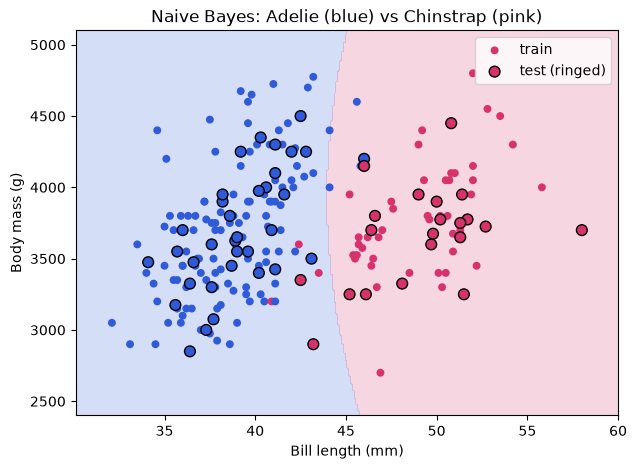

In [7]:
# a grid over the real units (mm and grams), scaled the same way as the training data
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)

colors = ['#2f5bd8', '#d6336c']
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.2, levels=[-0.5, 0.5, 1.5], colors=colors)
plt.scatter(X_train[:, 0], X_train[:, 1], c=[colors[v] for v in y_train], s=22, label='train')
plt.scatter(X_test[:, 0], X_test[:, 1], c=[colors[v] for v in y_test], s=60, facecolors='none', edgecolors='black', label='test (ringed)')
plt.xlabel('Bill length (mm)')
plt.ylabel('Body mass (g)')
plt.title('Naive Bayes: Adelie (blue) vs Chinstrap (pink)')
plt.legend()
plt.show()

## Try it yourself

- Print `classifier.theta_` to see the average of each feature per species.
- Naive Bayes assumes features are independent. Do bill length and body mass move together? Check with `dataset[['bill_length_mm', 'body_mass_g']].corr()`.

## See it: the decision boundary

Each coloured area is where the model answers "Adelie" (blue) or "Chinstrap" (raspberry). **Notice how** the boundary is a smooth curve, because it compares how likely each species is at every point. The left panel shows the penguins the model learned from (filled dots). The right panel shows the penguins it has never seen (ringed dots): a ring sitting inside the wrong colour is a mistake. The accuracy is in each title.

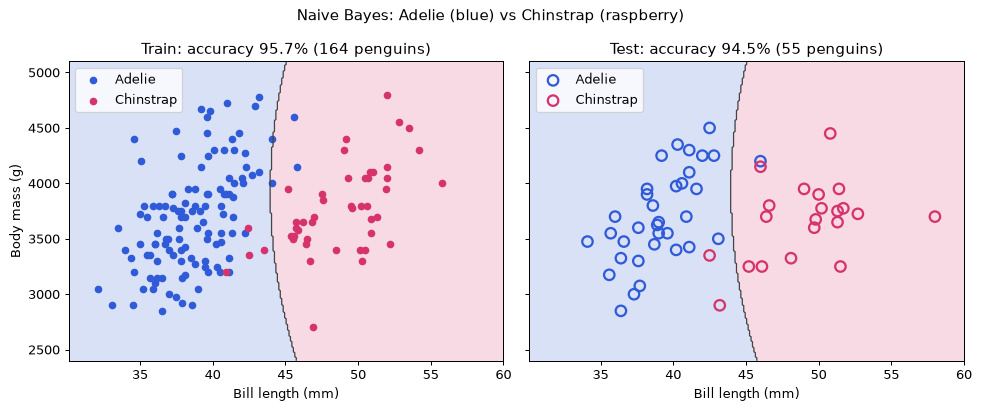

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 2, X[:, 0].max() + 2, 300),
                     np.linspace(X[:, 1].min() - 300, X[:, 1].max() + 300, 300))
zz = classifier.predict(sc.transform(np.c_[xx.ravel(), yy.ravel()])).reshape(xx.shape)
colors = [BLUE, PINK]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, name, Xp, yp, Xs in [(axes[0], 'Train', X_train, y_train, X_train_s),
                             (axes[1], 'Test', X_test, y_test, X_test_s)]:
    ax.contourf(xx, yy, zz, alpha=0.18, levels=[-0.5, 0.5, 1.5], colors=colors)
    ax.contour(xx, yy, zz, levels=[0.5], colors='#444444', linewidths=1)
    acc = (classifier.predict(Xs) == yp).mean()
    for cls, label in [(0, 'Adelie'), (1, 'Chinstrap')]:
        pts = Xp[yp == cls]
        if name == 'Train':
            ax.scatter(pts[:, 0], pts[:, 1], color=colors[cls], s=26, label=label)
        else:
            ax.scatter(pts[:, 0], pts[:, 1], facecolors='none', edgecolors=colors[cls], s=70, linewidths=1.8, label=label)
    ax.set_title(f'{name}: accuracy {acc:.1%} ({len(Xp)} penguins)')
    ax.set_xlabel('Bill length (mm)')
    ax.legend(loc='upper left')
axes[0].set_ylabel('Body mass (g)')
fig.suptitle('Naive Bayes: Adelie (blue) vs Chinstrap (raspberry)')
fig.tight_layout()
plt.show()
